### Part 1 — Understand the original dataset

In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = "data/penguins.csv"
df = pd.read_csv(path)
rows, columns = df.shape
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


1- number of observations and attributes.

In [3]:
print(f"Number of observations: {rows}")
print(f"Number of attributes: {columns}")

Number of observations: 344
Number of attributes: 8


 number and percentage of penguins belonging to each species and island.

In [4]:
number_of_species = df["species"].value_counts()
number_of_islands = df["island"].value_counts()
percentage_of_species = df["species"].value_counts(normalize=True) * 100
percentage_of_islands = df["island"].value_counts(normalize=True) * 100


print(f"Number of species for each penguin: {number_of_species}")
print(f"Number of islands for each penguin: {number_of_islands}") 
print(f"Percentage of species for each penguin: {percentage_of_species}")
print(f"Percentage of islands for each penguin: {percentage_of_islands}")


Number of species for each penguin: species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Number of islands for each penguin: island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
Percentage of species for each penguin: species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: proportion, dtype: float64
Percentage of islands for each penguin: island
Biscoe       48.837209
Dream        36.046512
Torgersen    15.116279
Name: proportion, dtype: float64


Calculate the mean, median, and standard deviation of body mass, separately for each species and each island.

In [5]:
# for each species
species_stats = df.groupby("species")["body_mass_g"].agg(["mean", "median", "std"])

print(species_stats)

# for each island
island_stats = df.groupby("island")["body_mass_g"].agg(["mean", "median", "std"])

print(island_stats)

                  mean  median         std
species                                   
Adelie     3700.662252  3700.0  458.566126
Chinstrap  3733.088235  3700.0  384.335081
Gentoo     5076.016260  5000.0  504.116237
                  mean  median         std
island                                    
Biscoe     4716.017964  4775.0  782.855743
Dream      3712.903226  3687.5  416.644112
Torgersen  3706.372549  3700.0  445.107940


Create an appropriate visualization showing the distribution of species and islands

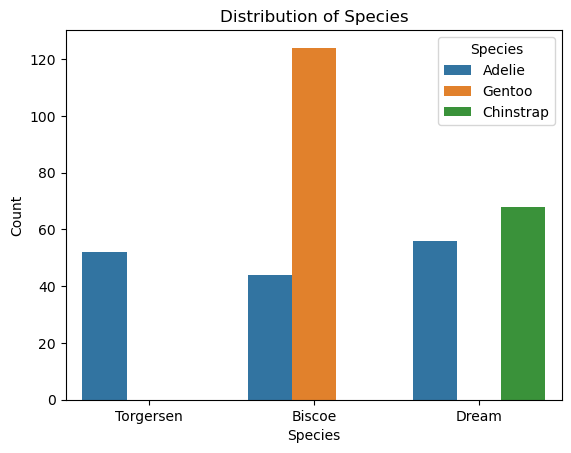

In [6]:
sns.countplot(data=df, x="island", hue="species")
plt.title("Distribution of Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.legend(title="Species")
plt.show()

### Part 2 — Generate 50 random splits

In [7]:
# Take a copy of the original dataframe
df_copy = df.copy()

results = []
splits = []

for i in range(50):

    # Step 1: Shuffle the dataset
    shuffled_df = df_copy.sample(frac=1, random_state=42 + i)

    n = len(shuffled_df)

    # Step 2: Calculate sizes
    train_size = round(n * 0.70)
    val_size = round(n * 0.20)
    test_size = n - train_size - val_size

    # Step 3: Split the dataset
    train = shuffled_df.iloc[:train_size].copy()
    val = shuffled_df.iloc[train_size:train_size + val_size].copy()
    test = shuffled_df.iloc[train_size + val_size:].copy()

    # Step 4: Calculate species proportions
    train_species = train["species"].value_counts(normalize=True)
    test_species = test["species"].value_counts(normalize=True)
    val_species = val["species"].value_counts(normalize=True)

    #  Step 4: Calculate island proportions\
    train_island = train["island"].value_counts(normalize=True)
    test_island = test["island"].value_counts(normalize=True)
    val_island = val["island"].value_counts(normalize=True)
    
    
    # Step 6: Verify the splits
    assert len(train) + len(val) + len(test) == n

    assert set(train.index).isdisjoint(set(val.index))
    assert set(train.index).isdisjoint(set(test.index))
    assert set(val.index).isdisjoint(set(test.index))

    # Step 7: Store proportions and sizes
    results.append({
        "candidate": i + 1,
        "train_size": len(train),
        "val_size": len(val),
        "test_size": len(test),
        "train_species": train_species.to_dict(),
        "val_species": val_species.to_dict(),
        "test_species": test_species.to_dict(),
        "train_island": train_island.to_dict(),
        "val_island": val_island.to_dict(),
        "test_island": test_island.to_dict()
    })

    # Step 8: Store the actual datasets
    splits.append({
        "candidate": i + 1,
        "train": train,
        "validation": val,
        "test": test
    })

# Step 9: Convert results to DataFrame
results_df = pd.DataFrame(results)

# Display results
print(results_df.head())

print("Total candidates:", len(results_df))

   candidate  train_size  val_size  test_size  \
0          1         241        69         34   
1          2         241        69         34   
2          3         241        69         34   
3          4         241        69         34   
4          5         241        69         34   

                                       train_species  \
0  {'Adelie': 0.44813278008298757, 'Gentoo': 0.35...   
1  {'Adelie': 0.46887966804979253, 'Gentoo': 0.36...   
2  {'Adelie': 0.4190871369294606, 'Gentoo': 0.365...   
3  {'Adelie': 0.42738589211618255, 'Gentoo': 0.36...   
4  {'Adelie': 0.44813278008298757, 'Gentoo': 0.34...   

                                         val_species  \
0  {'Adelie': 0.42028985507246375, 'Gentoo': 0.37...   
1  {'Adelie': 0.391304347826087, 'Gentoo': 0.3913...   
2  {'Adelie': 0.4927536231884058, 'Gentoo': 0.362...   
3  {'Adelie': 0.463768115942029, 'Gentoo': 0.3333...   
4  {'Adelie': 0.42028985507246375, 'Gentoo': 0.40...   

                               

Part 3 — Find the three closest distributions

In [9]:
original_species = df_copy["species"].value_counts(normalize=True) * 100
original_island = df_copy["island"].value_counts(normalize=True) * 100

print("Original species proportions:")
print(original_species)

print("\nOriginal island proportions:")
print(original_island)

Original species proportions:
species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: proportion, dtype: float64

Original island proportions:
island
Biscoe       48.837209
Dream        36.046512
Torgersen    15.116279
Name: proportion, dtype: float64


Compute the average of these differences to obtain one score for the candidate.

In [10]:
scores = []

for i in range(50):
  differences = []
  
  # Species proportions
  for split in ["train_species","val_species", "test_species"]:
    split_props = results_df.loc[i, split]
    for species in original_species.index:
      original = original_species[species]
      current = split_props.get(species, 0) * 100
      
      differences.append(abs(original - current))
  # Island proportions
  for split in ["train_island","val_island", "test_island"]:
    
    split_props = results_df.loc[i, split]
    for island in original_island.index:
      original = original_island[island]
      current = split_props.get(island, 0) * 100
      
      differences.append(abs(original - current))
    score = sum(differences) / len(differences)
  scores.append(score)

Rank all 50 candidates

In [11]:
# Add scores to results DataFrame
results_df["score"] = scores

# Rank candidates from smallest to largest score
ranked_candidates = results_df.sort_values(
    by="score", ascending=True
).reset_index(drop=True)

# Select the best 3 candidates
top_3 = ranked_candidates.head(3)

print("Top 3 Candidates:")
print(top_3[["candidate", "score"]])

Top 3 Candidates:
   candidate     score
0          5  1.626651
1          1  1.992521
2         50  2.070846


Compare proportions of the best 3 candidates

In [12]:
comparison = []

for _, row in top_3.iterrows():

    candidate = int(row["candidate"])

    for column, original_props in [
        ("species", original_species),
        ("island", original_island),
    ]:
        for category in original_props.index:
            comparison.append(
                {
                    "Candidate": candidate,
                    "Type": column,
                    "Category": category,
                    "Original (%)": original_props[category],
                    "Train (%)": row[f"train_{column}"].get(category, 0) * 100,
                    "Validation (%)": row[f"val_{column}"].get(category, 0) * 100,
                    "Test (%)": row[f"test_{column}"].get(category, 0) * 100,
                }
            )
    comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Candidate,Type,Category,Original (%),Train (%),Validation (%),Test (%)
0,5,species,Adelie,44.19,44.81,42.03,44.12
1,5,species,Gentoo,36.05,34.85,40.58,35.29
2,5,species,Chinstrap,19.77,20.33,17.39,20.59
3,5,island,Biscoe,48.84,47.72,53.62,47.06
4,5,island,Dream,36.05,36.51,33.33,38.24
5,5,island,Torgersen,15.12,15.77,13.04,14.71
6,1,species,Adelie,44.19,44.81,42.03,44.12
7,1,species,Gentoo,36.05,35.68,37.68,35.29
8,1,species,Chinstrap,19.77,19.50,20.29,20.59
9,1,island,Biscoe,48.84,47.72,49.28,55.88


Visualize the top 3 candidates' scores

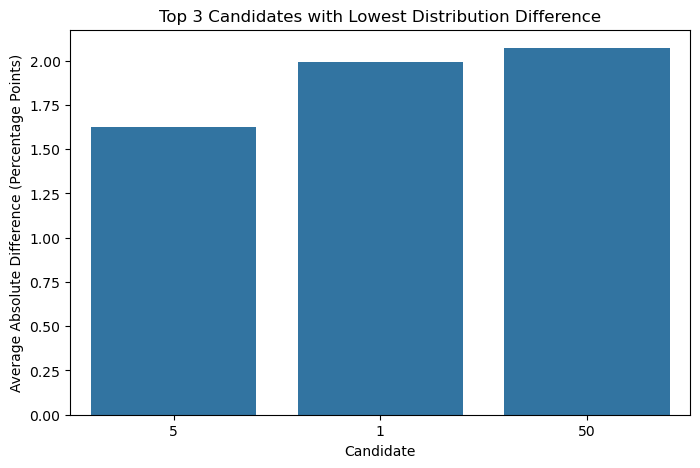

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=top_3,
    x="candidate",
    y="score",
    order=top_3["candidate"].tolist()
)

plt.title("Top 3 Candidates with Lowest Distribution Difference")
plt.xlabel("Candidate")
plt.ylabel("Average Absolute Difference (Percentage Points)")

plt.show()

Identify the best candidate

In [14]:
best_candidate = int(top_3.iloc[0]["candidate"])
best_score = top_3.iloc[0]["score"]

print("Best Candidate:", best_candidate)
print(f"Distribution Difference Score: {best_score:.4f} percentage points")

# Retrieve its actual datasets from Part 2
best_train = splits[best_candidate - 1]["train"]
best_val = splits[best_candidate - 1]["validation"]
best_test = splits[best_candidate - 1]["test"]

Best Candidate: 5
Distribution Difference Score: 1.6267 percentage points


Part 4 — Save your selected dataset

best candidate

In [15]:
# Select the candidate with the lowest score
best_candidate = int(top_3.iloc[0]["candidate"])

print("Best Candidate:", best_candidate)

# Get its training, validation, and test datasets
best_train = splits[best_candidate - 1]["train"]
best_val = splits[best_candidate - 1]["validation"]
best_test = splits[best_candidate - 1]["test"]

Best Candidate: 5


Add the split column & Save the CSV file

In [17]:
# Copy the original dataset
final_df = df.copy()

# Create a new column
final_df["split"] = ""

# Assign split labels using original row indices
final_df.loc[best_train.index, "split"] = "train"
final_df.loc[best_val.index, "split"] = "val"
final_df.loc[best_test.index, "split"] = "test"

# Display the result
display(final_df.head())

# Save the final dataset
final_df.to_csv("penguins_with_splits.csv", index=False)

print("Dataset saved successfully!")

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,split
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,train
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,val
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,train
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007,train
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,train


Dataset saved successfully!


 #### Data Science report

1- What did the original dataset reveal? 344 penguins, 3 species, and 3 islands. Adelie and Biscoe are the most common.

2- How did random sampling affect the distributions? Species and island proportions varied across the 50 splits, especially in smaller sets.

3- Which three candidates were closest to the original dataset? Candidates 5, 1, and 50 had the lowest scores, respectively.

4- Why did you select your final candidate? Candidate 5 was selected because its species and island proportions were closest overall to the original. Body-mass similarity was not verified. 

5- What are the limitations of your approach? The method ignores numerical features and does not guarantee reliable Machine Learning performance.